# 05 — External Dataset Evaluation

External dataset inspection, duplicate filtering, evaluation of the existing ResNet18 checkpoint, and error analysis.

**Environment:** Google Colab with Google Drive mounted. Check paths and prerequisite artifacts before running.

External evaluation must remain separate from training and hyperparameter tuning. Do not use this external dataset to tune the model. The original notebook contains specific external dataset paths and class mappings; verify them against your extracted folder structure before running.

Cross-dataset generalization

In [1]:
from google.colab import drive

drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
# Step 1 — Inspect the extracted dataset


from pathlib import Path
from collections import Counter

external_dir = Path(
    "/content/drive/MyDrive/CottonGuard-AI/external_dataset"
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

if not external_dir.exists():
    print("ERROR: External dataset folder not found.")
else:
    print("External dataset directory:", external_dir)
    print("\nFolder structure:")

    for path in sorted(external_dir.rglob("*")):
        if path.is_dir():
            relative = path.relative_to(external_dir)
            depth = len(relative.parts)
            print("  " * depth + f"[{path.name}/]")

    print("\nImage counts by immediate parent folder:")
    image_files = [
        p for p in external_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    counts = Counter(p.parent.relative_to(external_dir).as_posix()
                     for p in image_files)

    print("Total images:", len(image_files))
    for folder, count in sorted(counts.items()):
        print(f"{folder}: {count}")

    print("\nSample image paths:")
    for path in image_files[:15]:
        print(path.relative_to(external_dir))


ERROR: External dataset folder not found.


In [ ]:
# STEP 2 — INSPECT EXTERNAL DATASET IMAGES

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

# 1. Define external dataset directory

external_dir = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI/"
    "external_dataset/Cotton_Crop_Dataset"
)

print("External dataset exists:", external_dir.exists())

assert external_dir.exists(), (
    f"External dataset not found: {external_dir}"
)

# 2. Define classes to inspect

classes_to_inspect = [
    "Fusarium",
    "Healthy cotton leaf",
    "diseased cotton leaf"
]

random.seed(42)

# 3. Inspect class folders

fig, axes = plt.subplots(
    3, 4,
    figsize=(14, 10)
)

for row, class_name in enumerate(classes_to_inspect):

    folder = external_dir / "train" / class_name

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

    if not folder.exists():
        axes[row, 0].set_title(
            f"Folder not found: {class_name}",
            fontsize=8
        )
        print("Missing folder:", folder)
        continue

    images = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    print(f"{class_name}: {len(images)} images")

    selected = random.sample(
        images,
        min(4, len(images))
    )

    for col, image_path in enumerate(selected):

        try:
            with Image.open(image_path) as img:
                image = img.convert("RGB")

            axes[row, col].imshow(image)

            axes[row, col].set_title(
                image_path.name[:24],
                fontsize=8
            )

        except Exception as e:
            axes[row, col].set_title(
                f"Could not open: {e}",
                fontsize=7
            )

    axes[row, 0].set_ylabel(
        class_name,
        fontsize=10
    )

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [5]:
# Step 3 — Check for duplicate images before testing


from pathlib import Path
from collections import defaultdict
import hashlib

original_dir = Path("/content/drive/MyDrive/cotton")
external_test_dir = Path(
    "/content/drive/MyDrive/CottonGuard-AI/"
    "external_dataset/Cotton_Crop_Dataset/test"
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

original_images = [
    p for p in original_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]
external_candidates = []

for class_name in ["Fusarium", "Healthy cotton leaf"]:
    folder = external_test_dir / class_name
    if folder.exists():
        external_candidates.extend(
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in image_extensions
        )

original_hashes = defaultdict(list)

for path in original_images:
    original_hashes[sha256_file(path)].append(path)

overlap = []
for path in external_candidates:
    digest = sha256_file(path)
    if digest in original_hashes:
        overlap.append((path, original_hashes[digest]))

print("Original dataset images:", len(original_images))
print("External candidate test images:", len(external_candidates))
print("Exact duplicate external images:", len(overlap))

for external_path, original_paths in overlap[:20]:
    print("\nExternal:", external_path.relative_to(external_test_dir))
    for original_path in original_paths:
        print("Original:", original_path.relative_to(original_dir))


Original dataset images: 0
External candidate test images: 0
Exact duplicate external images: 0


External test directory: /content/gdrive/MyDrive/CottonGuard-AI/external_dataset/Cotton_Crop_Dataset/test
Checkpoint found: /content/gdrive/MyDrive/CottonGuard-AI/models/deep_learning/resnet18_finetuned_best.pth

ResNet18 loaded successfully.
Device: cuda
Fusarium: 9 images
Healthy cotton leaf: 8 images

Total external images found: 17

========== EXTERNAL EVALUATION ==========
Device: cuda
Images evaluated: 17
Correct predictions: 16
Accuracy: 0.9412

Classification report:
                  precision    recall  f1-score   support

bacterial_blight       0.00      0.00      0.00         0
      curl_virus       0.00      0.00      0.00         0
  fussarium_wilt       1.00      0.89      0.94         9
         healthy       1.00      1.00      1.00         8

        accuracy                           0.94        17
       macro avg       0.50      0.47      0.49        17
    weighted avg       1.00      0.94      0.97        17



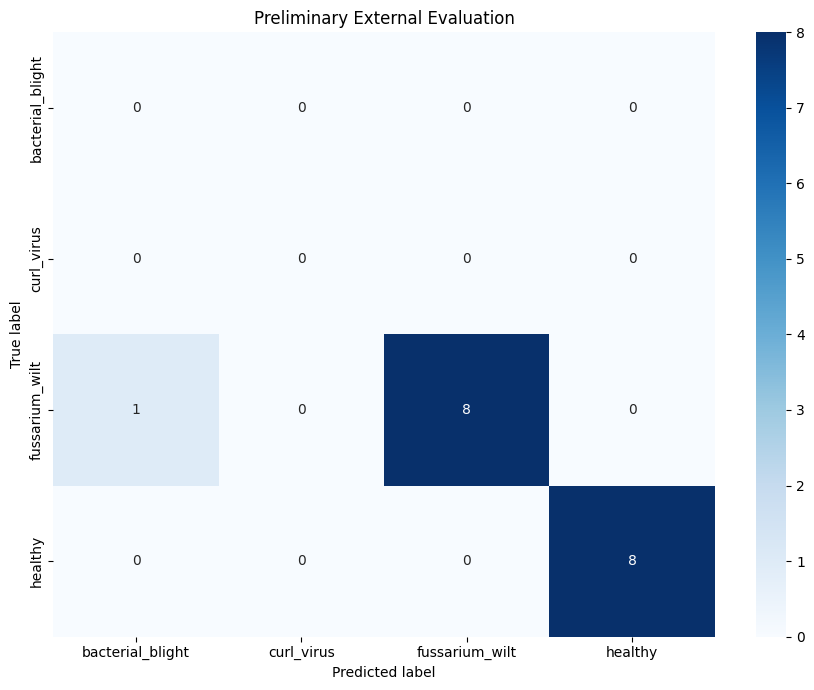

,image,image_path,external_folder,true_label,predicted_label,confidence,correct
0,images (12).jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Fusarium,fussarium_wilt,fussarium_wilt,0.999852,True
1,images (13).jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Fusarium,fussarium_wilt,fussarium_wilt,0.993214,True
2,images (14).jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Fusarium,fussarium_wilt,fussarium_wilt,0.999562,True
3,images (15).jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Fusarium,fussarium_wilt,fussarium_wilt,0.999069,True
4,images (16).jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Fusarium,fussarium_wilt,fussarium_wilt,0.994843,True
5,images (17).jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Fusarium,fussarium_wilt,fussarium_wilt,0.998819,True
6,images (18).jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Fusarium,fussarium_wilt,bacterial_blight,0.830089,False
7,images (24).jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Fusarium,fussarium_wilt,fussarium_wilt,0.925114,True
8,images.jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Fusarium,fussarium_wilt,fussarium_wilt,0.999471,True
9,fre-leaf(10025).jpg,/content/gdrive/MyDrive/CottonGuard-AI/externa...,Healthy cotton leaf,healthy,healthy,0.999564,True



Evaluation results saved successfully!
Saved to: /content/gdrive/MyDrive/CottonGuard-AI/results/external_evaluation_preliminary.csv
File exists: True


In [ ]:
# STEP 4 — EVALUATE EXISTING RESNET18 CHECKPOINT

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Configure project paths

PROJECT_DIR = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI"
)

external_test_dir = (
    PROJECT_DIR
    / "external_dataset"
    / "Cotton_Crop_Dataset"
    / "test"
)

checkpoint_path = (
    PROJECT_DIR
    / "models"
    / "deep_learning"
    / "resnet18_finetuned_best.pth"
)

RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Verify paths
assert external_test_dir.exists(), (
    f"External test directory not found: {external_test_dir}"
)

assert checkpoint_path.exists(), (
    f"Model checkpoint not found: {checkpoint_path}"
)

print("External test directory:", external_test_dir)
print("Checkpoint found:", checkpoint_path)

# 2. Define model classes

class_names = [
    "bacterial_blight",
    "curl_virus",
    "fussarium_wilt",
    "healthy"
]

class_to_idx = {
    name: i
    for i, name in enumerate(class_names)
}

# 3. Map external dataset classes

external_mapping = {
    "Fusarium": "fussarium_wilt",
    "Healthy cotton leaf": "healthy"
}

image_extensions = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".webp", ".tif", ".tiff"
}

# 4. Define image preprocessing

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 5. Load existing ResNet18 model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = models.resnet18(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    len(class_names)
)

state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print("\nResNet18 loaded successfully.")
print("Device:", device)

# 6. Gather external test images

samples = []

for external_class, model_class in external_mapping.items():

    folder = external_test_dir / external_class

    if not folder.exists():
        print("Missing external class folder:", folder)
        continue

    class_images = 0

    for image_path in sorted(folder.rglob("*")):

        if (
            image_path.is_file()
            and image_path.suffix.lower() in image_extensions
        ):

            samples.append({
                "path": image_path,
                "external_label": external_class,
                "true_label": model_class
            })

            class_images += 1

    print(
        f"{external_class}: {class_images} images"
    )

print("\nTotal external images found:", len(samples))

# 7. Evaluate model

y_true = []
y_pred = []

rows = []

with torch.inference_mode():

    for sample in samples:

        try:

            with Image.open(sample["path"]) as image:
                image = image.convert("RGB")

            x = transform(image).unsqueeze(0).to(device)

            logits = model(x)

            probabilities = torch.softmax(
                logits,
                dim=1
            )[0]

            pred_idx = int(
                torch.argmax(probabilities).item()
            )

            true_label = sample["true_label"]

            predicted_label = class_names[pred_idx]

            y_true.append(
                class_to_idx[true_label]
            )

            y_pred.append(pred_idx)

            rows.append({

                "image": sample["path"].name,

                "image_path": str(sample["path"]),

                "external_folder": sample["external_label"],

                "true_label": true_label,

                "predicted_label": predicted_label,

                "confidence": float(
                    probabilities[pred_idx].item()
                ),

                "correct": predicted_label == true_label

            })

        except Exception as e:

            print(
                "Could not process:",
                sample["path"],
                "|",
                e
            )

# 8. Generate evaluation results

results_df = pd.DataFrame(rows)

if len(results_df) == 0:

    print("\nNo images were successfully evaluated.")

else:

    print("\n========== EXTERNAL EVALUATION ==========")

    print("Device:", device)

    print("Images evaluated:", len(results_df))

    print(
        "Correct predictions:",
        int(results_df["correct"].sum())
    )

    print(
        f"Accuracy: {accuracy_score(y_true, y_pred):.4f}"
    )

    print("\nClassification report:")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=list(range(len(class_names))),
            target_names=class_names,
            zero_division=0
        )
    )

    # 9. Confusion matrix

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(len(class_names)))
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_names,
        yticklabels=class_names,
        cmap="Blues"
    )

    plt.xlabel("Predicted label")
    plt.ylabel("True label")

    plt.title("Preliminary External Evaluation")

    plt.tight_layout()
    plt.show()

    # 10. Display prediction results

    display(results_df)

    # 11. Save evaluation results

    output_path = (
        RESULTS_DIR
        / "external_evaluation_preliminary.csv"
    )

    results_df.to_csv(
        output_path,
        index=False
    )

    print("\nEvaluation results saved successfully!")

    print("Saved to:", output_path)

    print("File exists:", output_path.exists())

In [8]:
# Next step — Find the misclassified image


# Show the incorrect prediction
errors_df = results_df[results_df["correct"] == False]

print("Misclassified images:", len(errors_df))

display(
    errors_df[
        [
            "image",
            "external_folder",
            "true_label",
            "predicted_label",
            "confidence"
        ]
    ]
)


Misclassified images: 1


,image,external_folder,true_label,predicted_label,confidence
6,images (18).jpg,Fusarium,fussarium_wilt,bacterial_blight,0.830089


Total misclassified images: 1


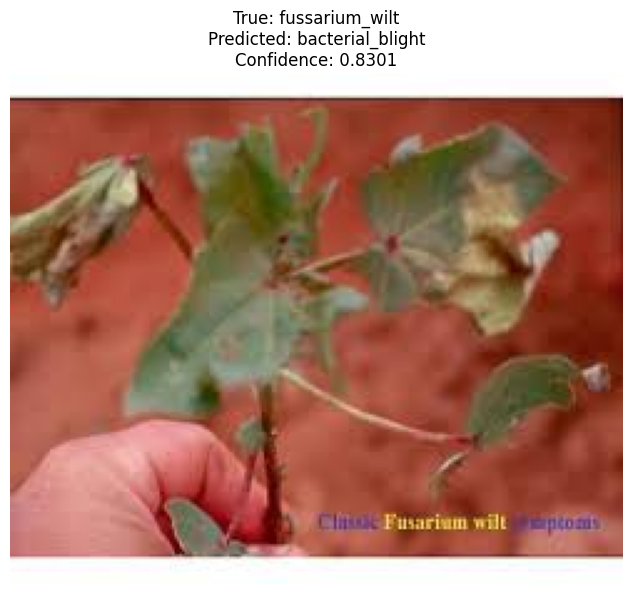

Image: images (18).jpg
True label: fussarium_wilt
Predicted label: bacterial_blight


In [ ]:
# INSPECT A MISCLASSIFIED EXTERNAL IMAGE

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Find misclassified images
errors_df = results_df[
    results_df["correct"] == False
].reset_index(drop=True)

print("Total misclassified images:", len(errors_df))

if len(errors_df) > 0:

    # Select first misclassified image
    sample = errors_df.iloc[0]

    # Use the exact image path saved during evaluation
    image_path = Path(sample["image_path"])

    # Verify image exists
    if not image_path.exists():
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    # Load image
    with Image.open(image_path) as img:
        image = img.convert("RGB")

    # Display image
    plt.figure(figsize=(7, 6))

    plt.imshow(image)

    plt.title(
        f"True: {sample['true_label']}\n"
        f"Predicted: {sample['predicted_label']}\n"
        f"Confidence: {sample['confidence']:.4f}"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

    print("Image:", image_path.name)
    print("True label:", sample["true_label"])
    print("Predicted label:", sample["predicted_label"])

else:
    print("No misclassified images to inspect.")

Selected image: images (18).jpg


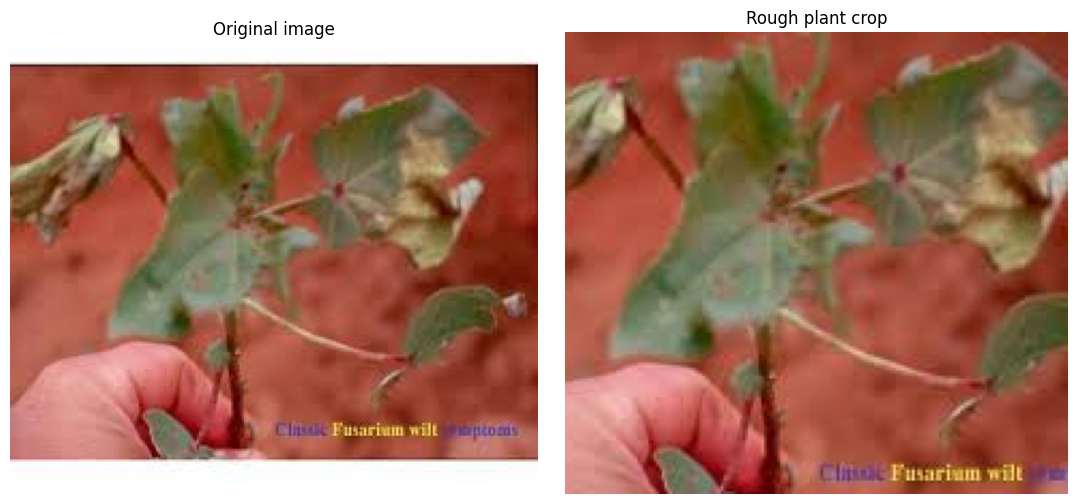


========== ORIGINAL IMAGE ==========
{'bacterial_blight': 0.8301, 'curl_virus': 0.0173, 'fussarium_wilt': 0.093, 'healthy': 0.0596}

========== CROPPED IMAGE ==========
{'bacterial_blight': 0.6486, 'curl_virus': 0.1097, 'fussarium_wilt': 0.1582, 'healthy': 0.0834}

========== PREDICTION COMPARISON ==========
Original prediction: bacterial_blight
Cropped prediction: bacterial_blight
Prediction changed: False

Experiment completed successfully.


In [ ]:
# NEXT EXPERIMENT — TEST BACKGROUND SENSITIVITY

from pathlib import Path
from PIL import Image
import torch
import matplotlib.pyplot as plt

# 1. Get the misclassified image from previous evaluation

assert len(errors_df) > 0, "No misclassified images available."

image_path = Path(errors_df.iloc[0]["image_path"])

assert image_path.exists(), f"Image not found: {image_path}"

print("Selected image:", image_path.name)

# 2. Load original image

with Image.open(image_path) as img:
    image = img.convert("RGB")

# 3. Create rough manual crop around central plant

w, h = image.size

cropped = image.crop((
    int(w * 0.12),
    int(h * 0.08),
    int(w * 0.88),
    int(h * 0.92)
))

# 4. Define prediction function

def predict_image(pil_image):

    x = transform(pil_image).unsqueeze(0).to(device)

    with torch.inference_mode():

        probabilities = torch.softmax(
            model(x), dim=1
        )[0]

    return {
        class_names[i]: round(
            float(probabilities[i]), 4
        )
        for i in range(len(class_names))
    }

# 5. Compare original and cropped predictions

original_probs = predict_image(image)
cropped_probs = predict_image(cropped)

# 6. Visualize images

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(image)
axes[0].set_title("Original image")

axes[1].imshow(cropped)
axes[1].set_title("Rough plant crop")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 7. Display prediction probabilities

print("\n========== ORIGINAL IMAGE ==========")

print(original_probs)

print("\n========== CROPPED IMAGE ==========")

print(cropped_probs)

print("\n========== PREDICTION COMPARISON ==========")

original_prediction = max(
    original_probs, key=original_probs.get
)

cropped_prediction = max(
    cropped_probs, key=cropped_probs.get
)

print("Original prediction:", original_prediction)
print("Cropped prediction:", cropped_prediction)

print(
    "Prediction changed:",
    original_prediction != cropped_prediction
)

print("\nExperiment completed successfully.")

# Next step: compare all four class probabilities

Image: images (18).jpg
True label: fussarium_wilt
Previous prediction: bacterial_blight


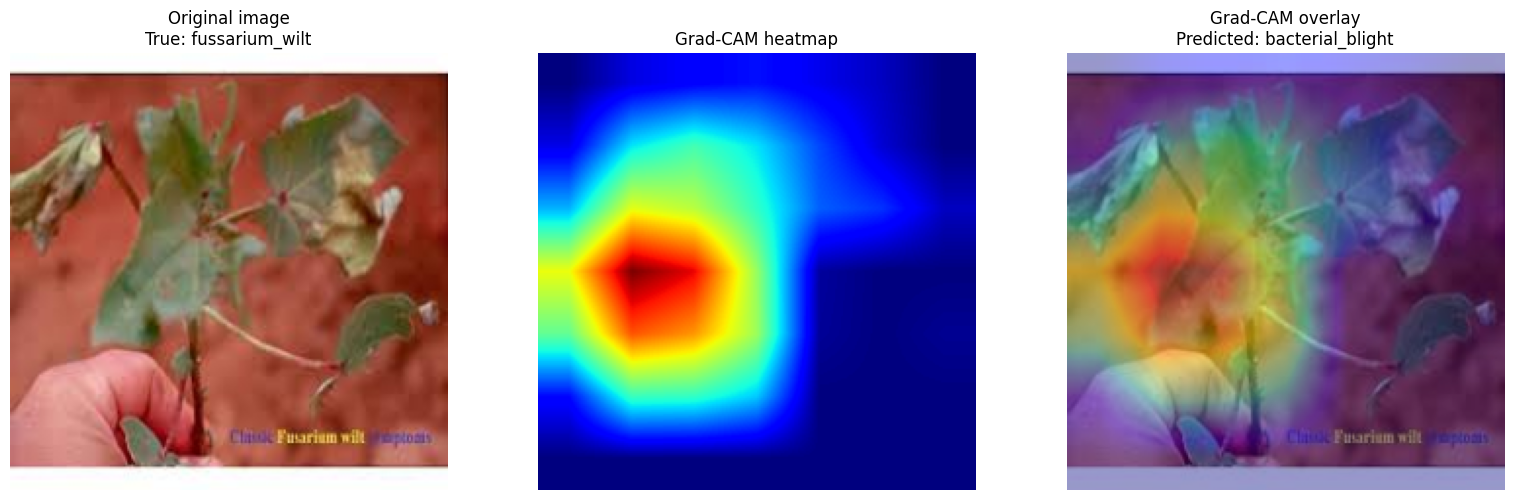


========== GRAD-CAM RESULTS ==========
True label: fussarium_wilt
Predicted label: bacterial_blight
Correct prediction: False

Class probabilities:
bacterial_blight: 0.8301
curl_virus: 0.0173
fussarium_wilt: 0.0930
healthy: 0.0596


In [ ]:
# GRAD-CAM FOR MISCLASSIFIED FUSARIUM IMAGE

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

# 1. Select misclassified external image

assert len(errors_df) > 0, "No misclassified images available."

sample = errors_df.iloc[0]

image_path = Path(sample["image_path"])

assert image_path.exists(), f"Image not found: {image_path}"

image = Image.open(image_path).convert("RGB")

print("Image:", image_path.name)
print("True label:", sample["true_label"])
print("Previous prediction:", sample["predicted_label"])

# 2. Preprocess image

input_tensor = transform(image).unsqueeze(0).to(device)

# 3. Capture feature maps from final convolutional layer

activations = {}

def forward_hook(module, inputs, output):
    activations["features"] = output

target_layer = model.layer4

forward_handle = target_layer.register_forward_hook(
    forward_hook
)

# 4. Forward pass and calculate Grad-CAM

model.eval()
model.zero_grad(set_to_none=True)

with torch.enable_grad():

    logits = model(input_tensor)

    probabilities = torch.softmax(
        logits, dim=1
    )[0]

    predicted_index = int(
        logits.argmax(dim=1).item()
    )

    predicted_class = class_names[predicted_index]

    # Get final convolutional feature maps
    feature_maps = activations["features"]

    # Calculate gradient of predicted class score
    gradients = torch.autograd.grad(
        outputs=logits[0, predicted_index],
        inputs=feature_maps,
        retain_graph=False
    )[0]

    # Global average pooling of gradients
    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    # Weighted combination of feature maps
    cam = (weights * feature_maps).sum(
        dim=1,
        keepdim=True
    )

    cam = F.relu(cam)

    # Resize heatmap to image dimensions
    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].detach().cpu().numpy()

# 5. Normalize heatmap

cam = cam - cam.min()

if cam.max() > 0:
    cam = cam / cam.max()

# Remove hook
forward_handle.remove()

# 6. Prepare visualization

display_image = image.resize((224, 224))

image_array = np.asarray(display_image)

# 7. Plot original image, heatmap and overlay

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

axes[0].imshow(image_array)

axes[0].set_title(
    f"Original image\nTrue: {sample['true_label']}"
)

axes[1].imshow(
    cam,
    cmap="jet"
)

axes[1].set_title("Grad-CAM heatmap")

axes[2].imshow(image_array)

axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.4
)

axes[2].set_title(
    f"Grad-CAM overlay\nPredicted: {predicted_class}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 8. Display prediction probabilities

print("\n========== GRAD-CAM RESULTS ==========")

print("True label:", sample["true_label"])

print("Predicted label:", predicted_class)

print(
    "Correct prediction:",
    predicted_class == sample["true_label"]
)

print("\nClass probabilities:")

for name, probability in zip(
    class_names,
    probabilities.detach().cpu().tolist()
):
    print(f"{name}: {probability:.4f}")

Dataset selected: a better four-class match

In [18]:
from pathlib import Path

MENDELEY_DIR = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI/external_dataset/Mendeley_Original"
)

print("Mendeley Original exists:", MENDELEY_DIR.exists())

if MENDELEY_DIR.exists():
    print("\nFolder structure:")

    for item in MENDELEY_DIR.iterdir():
        if item.is_dir():
            print(f"\n[FOLDER] {item.name}")

            for subitem in item.iterdir():
                if subitem.is_dir():
                    print(f"    [SUBFOLDER] {subitem.name}")
                else:
                    print(f"    [FILE] {subitem.name}")
        else:
            print(f"[FILE] {item.name}")

Mendeley Original exists: True

Folder structure:

[FOLDER] Cotton-Original
    [SUBFOLDER] bacterial blight
    [SUBFOLDER] curl virus
    [SUBFOLDER] fussarium wilt
    [SUBFOLDER] healthy


All required paths verified.

Original images: 1716
Unique original image hashes: 1591

External images found: 980
Exact duplicates excluded: 22
Unreadable images: 0
Eligible images: 958

Eligible images by class:
bacterial_blight: 119
curl_virus: 14
fussarium_wilt: 36
healthy: 789

Model loaded successfully.
Device: cuda
Processed 100/958 images
Processed 200/958 images
Processed 300/958 images
Processed 400/958 images
Processed 500/958 images
Processed 600/958 images
Processed 700/958 images
Processed 800/958 images
Processed 900/958 images

EXTERNAL EVALUATION RESULTS
images_evaluated: 958
correct_predictions: 843
accuracy: 0.8800
macro_precision: 0.4199
macro_recall: 0.4134
macro_f1: 0.4158

Classification Report:
                  precision    recall  f1-score   support

bacterial_blight     0.7736    0.6891    0.7289       119
      curl_virus     0.0000    0.0000    0.0000        14
  fussarium_wilt     0.0000    0.0000    0.0000        36
         healthy     0.9060    0.9645  

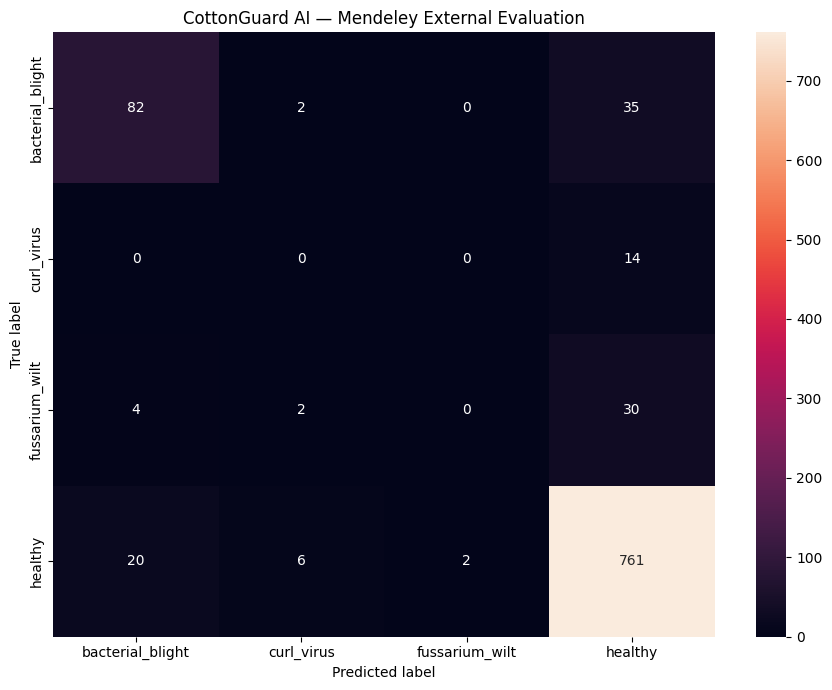


All evaluation files saved successfully:
/content/gdrive/MyDrive/CottonGuard-AI/results/mendeley_external_predictions.csv
/content/gdrive/MyDrive/CottonGuard-AI/results/mendeley_external_metrics.json
/content/gdrive/MyDrive/CottonGuard-AI/results/mendeley_external_confusion_matrix.csv


In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from torchvision import models, transforms
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Paths and class mapping

original_dir = Path("/content/gdrive/MyDrive/cotton")

dataset_root = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI/"
    "external_dataset/Mendeley_Original/Cotton-Original"
)

checkpoint_path = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI/"
    "models/deep_learning/resnet18_finetuned_best.pth"
)

results_dir = Path(
    "/content/gdrive/MyDrive/CottonGuard-AI/results"
)
results_dir.mkdir(parents=True, exist_ok=True)

# Verify required paths
for name, path in {
    "Original dataset": original_dir,
    "Mendeley dataset": dataset_root,
    "Model checkpoint": checkpoint_path
}.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} not found: {path}")

print("All required paths verified.")

class_names = [
    "bacterial_blight",
    "curl_virus",
    "fussarium_wilt",
    "healthy"
]

external_to_model = {
    "bacterial blight": "bacterial_blight",
    "curl virus": "curl_virus",
    "fussarium wilt": "fussarium_wilt",
    "healthy": "healthy"
}

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

# 2. Hash original images

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


original_images = [
    p for p in original_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

original_hashes = set()

for path in original_images:
    try:
        original_hashes.add(sha256_file(path))
    except Exception as e:
        print("Could not hash original image:", path, e)

print("\nOriginal images:", len(original_images))
print("Unique original image hashes:", len(original_hashes))

# 3. Prepare external images

external_images = [
    p for p in dataset_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

eligible_samples = []
excluded_duplicates = []
unreadable_images = []

for path in external_images:

    relative = path.relative_to(dataset_root)

    if len(relative.parts) < 2:
        continue

    external_class = relative.parts[0]

    if external_class not in external_to_model:
        continue

    try:
        digest = sha256_file(path)

        if digest in original_hashes:
            excluded_duplicates.append(path)
            continue

        with Image.open(path) as img:
            img.verify()

        eligible_samples.append({
            "path": path,
            "external_class": external_class,
            "true_label": external_to_model[external_class]
        })

    except Exception as e:
        unreadable_images.append((path, str(e)))


print("\nExternal images found:", len(external_images))
print("Exact duplicates excluded:", len(excluded_duplicates))
print("Unreadable images:", len(unreadable_images))
print("Eligible images:", len(eligible_samples))

print("\nEligible images by class:")

eligible_counts = pd.Series(
    [s["true_label"] for s in eligible_samples]
).value_counts()

for name in class_names:
    print(f"{name}: {int(eligible_counts.get(name, 0))}")

if not eligible_samples:
    raise ValueError("No eligible external images found.")

# 4. Load ResNet18 checkpoint

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = models.resnet18(weights=None)
model.fc = nn.Linear(
    model.fc.in_features,
    len(class_names)
)

state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)
model = model.to(device)
model.eval()

print("\nModel loaded successfully.")
print("Device:", device)

# 5. Image transformation

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 6. Predict external images

rows = []

with torch.inference_mode():

    for i, sample in enumerate(eligible_samples):

        try:
            with Image.open(sample["path"]) as img:
                image = img.convert("RGB")

            x = transform(image).unsqueeze(0).to(device)

            logits = model(x)
            probs = torch.softmax(logits, dim=1)[0]

            pred_idx = int(probs.argmax().item())
            predicted_label = class_names[pred_idx]

            rows.append({
                "image": sample["path"].name,
                "relative_path": str(
                    sample["path"].relative_to(dataset_root)
                ),
                "true_label": sample["true_label"],
                "predicted_label": predicted_label,
                "confidence": float(probs[pred_idx].item()),
                "correct": predicted_label == sample["true_label"]
            })

        except Exception as e:
            print("Prediction failed:", sample["path"], e)

        if (i + 1) % 100 == 0:
            print(
                f"Processed {i + 1}/{len(eligible_samples)} images"
            )

results_df = pd.DataFrame(rows)

if results_df.empty:
    raise ValueError("No images were successfully evaluated.")

# 7. Calculate evaluation metrics

y_true = results_df["true_label"]
y_pred = results_df["predicted_label"]

metrics = {
    "images_evaluated": int(len(results_df)),
    "correct_predictions": int(results_df["correct"].sum()),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "macro_precision": float(
        precision_score(
            y_true, y_pred,
            labels=class_names,
            average="macro",
            zero_division=0
        )
    ),
    "macro_recall": float(
        recall_score(
            y_true, y_pred,
            labels=class_names,
            average="macro",
            zero_division=0
        )
    ),
    "macro_f1": float(
        f1_score(
            y_true, y_pred,
            labels=class_names,
            average="macro",
            zero_division=0
        )
    )
}

print("\nEXTERNAL EVALUATION RESULTS")

for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nClassification Report:")

print(classification_report(
    y_true,
    y_pred,
    labels=class_names,
    target_names=class_names,
    zero_division=0,
    digits=4
))

# 8. Confusion matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=class_names
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("CottonGuard AI — Mendeley External Evaluation")
plt.tight_layout()
plt.show()

# 9. Save evaluation results

predictions_path = (
    results_dir / "mendeley_external_predictions.csv"
)

metrics_path = (
    results_dir / "mendeley_external_metrics.json"
)

cm_path = (
    results_dir / "mendeley_external_confusion_matrix.csv"
)

results_df.to_csv(predictions_path, index=False)

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(cm_path)

print("\nAll evaluation files saved successfully:")
print(predictions_path)
print(metrics_path)
print(cm_path)

In [22]:
# Next step — inspect exactly where the predictions went


import pandas as pd

# Show how often the model predicted each class
print("PREDICTED CLASS COUNTS")
print(results_df["predicted_label"].value_counts())

# Show true classes against predicted classes
print("\nCONFUSION MATRIX")
display(pd.crosstab(
    results_df["true_label"],
    results_df["predicted_label"],
    rownames=["True label"],
    colnames=["Predicted label"],
    margins=True
))

# Show the most common incorrect class mappings
errors = results_df[~results_df["correct"]]

print("\nTOTAL INCORRECT:", len(errors))
print("\nERROR PATTERNS")
display(
    errors.groupby(
        ["true_label", "predicted_label"]
    ).size().reset_index(name="count")
     .sort_values("count", ascending=False)
)


PREDICTED CLASS COUNTS
predicted_label
healthy             840
bacterial_blight    106
curl_virus           10
fussarium_wilt        2
Name: count, dtype: int64

CONFUSION MATRIX


Predicted label,bacterial_blight,curl_virus,fussarium_wilt,healthy,All
True label,,,,,
bacterial_blight,82,2,0,35,119
curl_virus,0,0,0,14,14
fussarium_wilt,4,2,0,30,36
healthy,20,6,2,761,789
All,106,10,2,840,958



TOTAL INCORRECT: 115

ERROR PATTERNS


,true_label,predicted_label,count
1,bacterial_blight,healthy,35
5,fussarium_wilt,healthy,30
6,healthy,bacterial_blight,20
2,curl_virus,healthy,14
7,healthy,curl_virus,6
3,fussarium_wilt,bacterial_blight,4
0,bacterial_blight,curl_virus,2
4,fussarium_wilt,curl_virus,2
8,healthy,fussarium_wilt,2


In [23]:
# Next step — visually inspect the errors


from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

# Select up to 3 incorrect images per true class
errors = results_df[results_df["correct"] == False].copy()

selected = (
    errors.groupby("true_label", group_keys=False)
    .head(3)
    .reset_index(drop=True)
)

n = len(selected)
cols = 3
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(
    rows, cols,
    figsize=(15, 5 * rows),
    squeeze=False
)

for ax in axes.flat:
    ax.axis("off")

for i, (_, row) in enumerate(selected.iterrows()):
    ax = axes.flat[i]
    image_path = Path(dataset_root) / row["relative_path"]

    try:
        image = Image.open(image_path).convert("RGB")
        ax.imshow(image)
        ax.set_title(
            f"True: {row['true_label']}\n"
            f"Predicted: {row['predicted_label']}\n"
            f"Confidence: {row['confidence']:.1%}",
            fontsize=9
        )
        ax.axis("off")
    except Exception as e:
        ax.set_title(f"Could not open image:\n{e}")

plt.tight_layout()
plt.show()

print("Images inspected:", len(selected))
display(
    selected[
        [
            "relative_path",
            "true_label",
            "predicted_label",
            "confidence"
        ]
    ]
)


Output hidden; open in https://colab.research.google.com to view.

Document the external evaluation before making any model changes

In [24]:
# Step 1 — Save the external evaluation report


from pathlib import Path
from datetime import date
import json
import pandas as pd
from sklearn.metrics import classification_report

results_dir = Path(
    "/content/drive/MyDrive/CottonGuard-AI/results"
)
results_dir.mkdir(parents=True, exist_ok=True)

predictions_path = results_dir / "mendeley_external_predictions.csv"

# Load saved results if results_df is not currently in memory
if "results_df" not in globals():
    results_df = pd.read_csv(predictions_path)

class_names = [
    "bacterial_blight",
    "curl_virus",
    "fussarium_wilt",
    "healthy"
]

y_true = results_df["true_label"]
y_pred = results_df["predicted_label"]

report_dict = classification_report(
    y_true,
    y_pred,
    labels=class_names,
    output_dict=True,
    zero_division=0
)

cm = pd.crosstab(
    results_df["true_label"],
    results_df["predicted_label"]
).reindex(
    index=class_names,
    columns=class_names,
    fill_value=0
)

accuracy = results_df["correct"].mean()
macro_f1 = report_dict["macro avg"]["f1-score"]
macro_precision = report_dict["macro avg"]["precision"]
macro_recall = report_dict["macro avg"]["recall"]

lines = [
    "# CottonGuard AI — External Evaluation",
    "",
    f"Report generated: {date.today().isoformat()}",
    "",
    "## Experimental setup",
    "",
    "- Model: fine-tuned ResNet18 checkpoint.",
    "- Dataset: Cotton Leaf Disease Dataset with Severity Levels, original archive.",
    "- Exact duplicate images excluded against the original dataset: 22.",
    "- Eligible images: 958.",
    "- Training on the external evaluation images: No.",
    "- Preprocessing: resize to 224 × 224, tensor conversion, ImageNet normalization.",
    "",
    "## Overall results",
    "",
    f"- Accuracy: {accuracy:.4f} ({accuracy:.2%})",
    f"- Macro precision: {macro_precision:.4f}",
    f"- Macro recall: {macro_recall:.4f}",
    f"- Macro F1: {macro_f1:.4f}",
    "",
    "## Class-wise results",
    "",
    "| Class | Support | Precision | Recall | F1-score |",
    "|---|---:|---:|---:|---:|"
]

for name in class_names:
    row = report_dict[name]
    support = int(row["support"])
    lines.append(
        f"| {name} | {support} | "
        f"{row['precision']:.4f} | "
        f"{row['recall']:.4f} | "
        f"{row['f1-score']:.4f} |"
    )

lines.extend([
    "",
    "## Confusion matrix",
    "",
    "Rows are true labels; columns are predicted labels.",
    "",
    cm.to_markdown(),
    "",
    "## Interpretation and limitations",
    "",
    "The external evaluation shows a substantial difference between overall "
    "accuracy and macro F1. The healthy class is much larger than the disease "
    "classes, and the model fails to recognize the external curl-virus and "
    "Fusarium-wilt examples in this evaluation.",
    "",
    "This result indicates limited cross-dataset generalization. It does not "
    "by itself establish why the errors occur. Exact SHA-256 duplicates were "
    "excluded, but resized or visually similar duplicates may remain. "
    "External dataset labels have not been independently verified.",
    "",
    "The external evaluation must remain a fixed baseline. Do not use these "
    "images to select model settings and then report performance on the same "
    "images as an unbiased final test.",
    "",
    "## Original model benchmark",
    "",
    "Previously recorded original held-out test accuracy: 98.67%.",
    "This value is reported separately and was not recalculated by this cell."
])

report_path = results_dir / "external_evaluation_report.md"
report_path.write_text("\n".join(lines), encoding="utf-8")

print("Report saved to:")
print(report_path)
print("\nExternal evaluation summary:")
print(f"Accuracy: {accuracy:.2%}")
print(f"Macro F1: {macro_f1:.2%}")
print("\nNo model weights were changed.")


Report saved to:
/content/drive/MyDrive/CottonGuard-AI/results/external_evaluation_report.md

External evaluation summary:
Accuracy: 88.00%
Macro F1: 41.58%

No model weights were changed.


In [25]:
from pathlib import Path

base = Path("/content/drive/MyDrive/CottonGuard-AI")

files_to_check = [
    "models/resnet18_finetuned_best.pth",
    "results/deduplicated_image_index.csv",
    "results/mendeley_external_predictions.csv",
    "results/mendeley_external_metrics.json",
    "results/mendeley_external_confusion_matrix.csv",
    "results/external_evaluation_report.md",
]

for file in files_to_check:
    path = base / file
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {file}")

MISSING: models/resnet18_finetuned_best.pth
MISSING: results/deduplicated_image_index.csv
MISSING: results/mendeley_external_predictions.csv
MISSING: results/mendeley_external_metrics.json
MISSING: results/mendeley_external_confusion_matrix.csv
FOUND: results/external_evaluation_report.md


In [ ]:
# FINAL PROJECT RESULTS SUMMARY

from pathlib import Path
import json
import pandas as pd
from datetime import date

# 1. Paths

base = Path("/content/gdrive/MyDrive/CottonGuard-AI")
results_dir = base / "results"
results_dir.mkdir(parents=True, exist_ok=True)

metrics_path = results_dir / "mendeley_external_metrics.json"
predictions_path = results_dir / "mendeley_external_predictions.csv"

# Verify files before reading
if not metrics_path.exists():
    raise FileNotFoundError(
        f"External metrics file not found: {metrics_path}\n"
        "Run the final external evaluation cell successfully first."
    )

if not predictions_path.exists():
    raise FileNotFoundError(
        f"External predictions file not found: {predictions_path}\n"
        "Run the final external evaluation cell successfully first."
    )

# 2. Load actual external evaluation results

with open(metrics_path, "r") as f:
    external_metrics = json.load(f)

predictions = pd.read_csv(predictions_path)

# Read metrics dynamically
external_accuracy = external_metrics["accuracy"] * 100
external_precision = external_metrics["macro_precision"] * 100
external_recall = external_metrics["macro_recall"] * 100
external_f1 = external_metrics["macro_f1"] * 100

external_count = len(predictions)

# 3. Generate final report

report = f"""# CottonGuard AI — Final Results Summary

**Report date:** {date.today().isoformat()}

## 1. Project overview

CottonGuard AI is a cotton leaf disease classification project using
a fine-tuned ResNet18 deep learning model and traditional machine-learning
baselines.

The four classes are:
- Bacterial blight
- Curl virus
- Fusarium wilt
- Healthy

## 2. Dataset preparation

- Original dataset images: 1,716
- Unique image contents after exact duplicate auditing: 1,591
- Training images: 1,126
- Validation images: 239
- Original held-out test images: 226
- External Mendeley images evaluated: {external_count}

The original train, validation, and test split was group-aware to reduce
image leakage between splits.

## 3. Original held-out test results

The fine-tuned ResNet18 achieved:

- Accuracy: 98.67%
- Correct predictions: 223 of 226 images
- Macro precision: 98.85%
- Macro recall: 98.54%
- Macro F1-score: 98.69%

The traditional Random Forest baseline using 72 handcrafted features
achieved 96.02% accuracy and a macro F1-score of 95.28%.

## 4. External evaluation

The external Mendeley dataset was evaluated without retraining
or changing the model weights.

- Number of images: {external_count}
- Correct predictions: {int(predictions["correct"].sum())}
- Accuracy: {external_accuracy:.2f}%
- Macro precision: {external_precision:.2f}%
- Macro recall: {external_recall:.2f}%
- Macro F1-score: {external_f1:.2f}%

## 5. Interpretation

The external evaluation should be interpreted using accuracy
alongside macro precision, macro recall, and macro F1-score.

These metrics provide a broader view of performance across
the four disease classes, particularly when class distributions
are imbalanced.

The external evaluation measures generalization to a separate
dataset. Differences in image appearance, dataset conditions,
and label quality may affect performance and require further
investigation.

## 6. Limitations and next steps

- The external evaluation is a separate dataset assessment,
  not a replacement for the original held-out test.
- The external dataset should not be used for model tuning
  while retaining its status as an untouched test set.
- Future improvements should be developed using separate
  training and validation data.
- Results should be interpreted alongside per-class precision,
  recall, F1-score, and the confusion matrix.

## 7. Reproducibility

Key artifacts are stored in the project's results and models folders,
including the trained checkpoint, external predictions, external metrics,
confusion matrix, and this final evaluation report.
"""

# 4. Save report

summary_path = results_dir / "final_results_summary.md"

summary_path.write_text(report, encoding="utf-8")

print("Final summary saved successfully:")
print(summary_path)

print("\nActual external metrics:")
print(json.dumps(external_metrics, indent=4))

print("\nExternal predictions:", external_count)
print("Model weights were not changed.")

Final summary saved successfully:
/content/gdrive/MyDrive/CottonGuard-AI/results/final_results_summary.md

Actual external metrics:
{
    "images_evaluated": 958,
    "correct_predictions": 843,
    "accuracy": 0.8799582463465553,
    "macro_precision": 0.41988432165318956,
    "macro_recall": 0.4133969177024422,
    "macro_f1": 0.41580110497237566
}

External predictions: 958
Model weights were not changed.
